# **Лабораторна робота № 8**
**Тема:** Модульне програмування, створення пакетів та системні бібліотеки.

**Мета:** Опанувати практичні навички проектування модульної архітектури програмного забезпечення мовою Python. Навчитися структурувати багатофайлові проекти у взаємопов'язані модулі та пакети з використанням файлів ініціалізації `__init__.py` і списків експорту `__all__`, організовувати автономні точки входу за допомогою ідіоми `if __name__ == '__main__':`, маніпулювати параметрами пошуку інтерпретатора у списку `sys.path`. Опанувати обробку параметрів командного рядка через список `sys.argv`, а також розробити системні консольні утиліти (CLI) для автоматизованого сканування, аналізу прав доступу та аудиту дискового простору файлової системи за допомогою модулів `sys`, `os` та `pathlib`.

**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

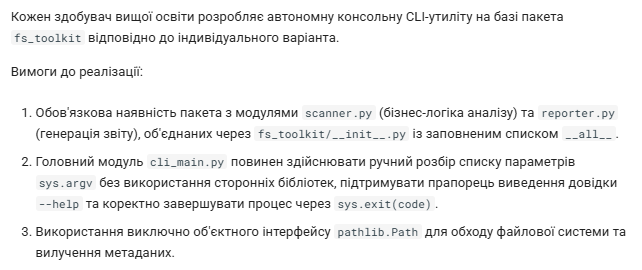

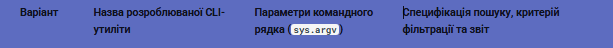
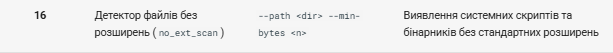

**1. Структура пакета `fs_toolkit` (`scanner.py`, `reporter.py`, `__init__.py`) та модуля `cli_main.py`**

In [1]:
from pathlib import Path
import sys

project_root = Path("lab08_variant16").resolve()
pkg_dir = project_root / "fs_toolkit"
pkg_dir.mkdir(parents=True, exist_ok=True)

scanner_py = r"""from pathlib import Path
import os
import time


def scan_extensionless_files(base_path: Path, min_bytes: int = 0) -> list[dict]:
    if not base_path.exists() or not base_path.is_dir():
        raise ValueError(f"Шлях '{base_path}' не існує або не є директорією.")
    if min_bytes < 0:
        raise ValueError("Мінімальний розмір (--min-bytes) не може бути від'ємним.")

    resolved_root = base_path.resolve()
    matched_files: list[dict] = []

    for item in resolved_root.rglob("*"):
        if not item.is_file():
            continue
        if item.suffix != "":
            continue

        try:
            stat_res = item.stat()
            file_size = stat_res.st_size
            if file_size < min_bytes:
                continue

            octal_permissions = oct(stat_res.st_mode & 0o777)
            is_executable = bool(stat_res.st_mode & 0o111)
            modified_at = time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(stat_res.st_mtime))

            with item.open("rb") as fh:
                header = fh.read(16)

            if header.startswith(b"#!"):
                file_kind = "script (shebang)"
            elif header.startswith(b"\x7fELF"):
                file_kind = "binary (ELF)"
            elif header.startswith(b"MZ"):
                file_kind = "binary (PE/MZ)"
            else:
                file_kind = "extensionless file"

            matched_files.append({
                "path": item,
                "relative_path": item.relative_to(resolved_root),
                "size_bytes": file_size,
                "size_kb": file_size / 1024.0,
                "modified_at": modified_at,
                "permissions": octal_permissions,
                "executable": is_executable,
                "kind": file_kind,
            })
        except (PermissionError, OSError) as err:
            print(f"Попередження системи: Немає доступу до файлу '{item}': {err}")
            continue

    matched_files.sort(key=lambda rec: (-rec["size_bytes"], str(rec["relative_path"])))
    return matched_files
"""

reporter_py = r"""def print_no_ext_report(file_records: list[dict], min_bytes: int, search_root: str) -> None:
    header_sep = "=" * 96
    row_sep = "-" * 96

    print("\n" + header_sep)
    print(f"{'NO_EXT_SCAN — ЗВІТ ПОШУКУ ФАЙЛІВ БЕЗ РОЗШИРЕНЬ':^96}")
    print(header_sep)
    print(f"Базова директорія пошуку : {search_root}")
    print(f"Мінімальний розмір файлу  : {min_bytes} байт")
    print(row_sep)
    print(
        f"| {'№':^3} | {'Файл':<26} | {'Розмір (Б)':>10} | "
        f"{'Права':^7} | {'Exec':^4} | {'Тип файлу':<24} |"
    )
    print(row_sep)

    total_bytes = 0
    for idx, rec in enumerate(file_records, start=1):
        total_bytes += rec["size_bytes"]
        rel_str = str(rec["relative_path"])
        if len(rel_str) > 26:
            rel_str = f"...{rel_str[-23:]}"
        exec_label = "YES" if rec["executable"] else "NO"
        print(
            f"| {idx:^3d} | {rel_str:<26} | {rec['size_bytes']:>10d} | "
            f"{rec['permissions']:^7} | {exec_label:^4} | {rec['kind']:<24} |"
        )

    print(header_sep)
    total_kb = total_bytes / 1024.0
    print(f"  Всього знайдено файлів без розширення: {len(file_records):>6d}")
    print(f"  Сумарний обсяг вибірки:               {total_bytes:>6d} Б ({total_kb:.2f} КБ)")
    print(header_sep + "\n")
"""

init_py = r"""from .scanner import scan_extensionless_files
from .reporter import print_no_ext_report

__all__ = [
    "scan_extensionless_files",
    "print_no_ext_report",
]
"""

cli_main_py = r"""import sys
import time
from pathlib import Path

_ROOT_DIR = Path(__file__).resolve().parent
if str(_ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(_ROOT_DIR))

from fs_toolkit import scan_extensionless_files, print_no_ext_report


def print_usage_help() -> None:
    print("ВИКОРИСТАННЯ:")
    print("    python cli_main.py --path <каталог> --min-bytes <байт>")
    print("    python cli_main.py --help")
    print()
    print("ПАРАМЕТРИ:")
    print("    --path <dir>     : Шлях до цільового каталогу (обов'язковий).")
    print("    --min-bytes <n>  : Мінімальний розмір файлу у байтах (обов'язковий, ціле >= 0).")
    print("    --help, -h       : Вивести цю довідку та завершити роботу.")


def parse_cli_arguments(args_list: list[str]) -> dict:
    if "--help" in args_list[1:] or "-h" in args_list[1:]:
        print_usage_help()
        sys.exit(0)

    config = {
        "path": None,
        "min_bytes": None,
    }

    i = 1
    while i < len(args_list):
        arg = args_list[i]
        if arg == "--path":
            if i + 1 >= len(args_list):
                print("Помилка: Після '--path' потрібно вказати шлях до каталогу.", file=sys.stderr)
                sys.exit(2)
            config["path"] = Path(args_list[i + 1]).resolve()
            i += 2
        elif arg == "--min-bytes":
            if i + 1 >= len(args_list):
                print("Помилка: Після '--min-bytes' потрібно вказати ціле число.", file=sys.stderr)
                sys.exit(2)
            try:
                val = int(args_list[i + 1])
            except ValueError:
                print("Помилка: '--min-bytes' має бути цілим числом.", file=sys.stderr)
                sys.exit(2)
            if val < 0:
                print("Помилка: '--min-bytes' не може бути від'ємним.", file=sys.stderr)
                sys.exit(2)
            config["min_bytes"] = val
            i += 2
        else:
            print(f"Помилка: Невідомий параметр '{arg}'.", file=sys.stderr)
            print_usage_help()
            sys.exit(2)

    if config["path"] is None:
        print("Помилка: Обов'язковий параметр '--path' не вказано.", file=sys.stderr)
        print_usage_help()
        sys.exit(2)

    if config["min_bytes"] is None:
        print("Помилка: Обов'язковий параметр '--min-bytes' не вказано.", file=sys.stderr)
        print_usage_help()
        sys.exit(2)

    return config


def main() -> None:
    cli_config = parse_cli_arguments(sys.argv)
    target_dir = cli_config["path"]
    min_bytes = cli_config["min_bytes"]

    t_start = time.perf_counter()
    try:
        results = scan_extensionless_files(base_path=target_dir, min_bytes=min_bytes)
    except ValueError as val_err:
        print(f"Помилка параметрів: {val_err}", file=sys.stderr)
        sys.exit(2)
    except Exception as exc:
        print(f"Помилка виконання: {exc}", file=sys.stderr)
        sys.exit(1)

    print_no_ext_report(results, min_bytes, str(target_dir))
    elapsed_ms = (time.perf_counter() - t_start) * 1000.0
    print(f"Операцію завершено за {elapsed_ms:.3f} мс.")
    sys.exit(0)


if __name__ == "__main__":
    main()
"""

(pkg_dir / "scanner.py").write_text(scanner_py, encoding="utf-8")
(pkg_dir / "reporter.py").write_text(reporter_py, encoding="utf-8")
(pkg_dir / "__init__.py").write_text(init_py, encoding="utf-8")
(project_root / "cli_main.py").write_text(cli_main_py, encoding="utf-8")

print("Каталог проєкту:", project_root)
print("Створені файли:", sorted(str(p.relative_to(project_root)) for p in project_root.rglob("*") if p.is_file()))
print("sys.path містить каталог проєкту:", str(project_root) in sys.path)

Каталог проєкту: D:\Діма\Програмування\Python\Приклади phyton\З університета\Python база\Labs\Lab8\lab08_variant16
Створені файли: ['cli_main.py', 'fs_toolkit\\__init__.py', 'fs_toolkit\\reporter.py', 'fs_toolkit\\scanner.py']
sys.path містить каталог проєкту: False


**2. Створення тестових файлів та запуск CLI-утиліти (`--help`, `--path`, `--min-bytes`)**

In [2]:
from pathlib import Path
import os
import subprocess
import sys

project_root = Path("lab08_variant16").resolve()
sandbox_dir = project_root / "test_sandbox"
nested_dir = sandbox_dir / "bin"
nested_dir.mkdir(parents=True, exist_ok=True)

script_file = nested_dir / "start_service"
script_file.write_bytes(b"#!/usr/bin/env bash\necho 'Starting service...'\nexit 0\n")
script_file.chmod(0o755)

elf_file = nested_dir / "core_worker"
elf_file.write_bytes(b"\x7fELF" + b"\x00" * 96)
elf_file.chmod(0o750)

small_file = nested_dir / "pid_lock"
small_file.write_bytes(b"1234")
small_file.chmod(0o644)

notes_file = sandbox_dir / "CHANGELOG"
notes_file.write_text("Release v1.0 without file extension.\n", encoding="utf-8")
notes_file.chmod(0o644)

ext_file = sandbox_dir / "settings.json"
ext_file.write_text('{"debug": false}', encoding="utf-8")

env = os.environ.copy()
env["PYTHONIOENCODING"] = "utf-8"

for title, args in [
    ("=== Тест 1: Довідка --help ===", ["--help"]),
    ("=== Тест 2: Сканування --path <dir> --min-bytes 20 ===", ["--path", str(sandbox_dir), "--min-bytes", "20"]),
    ("=== Тест 3: Відсутність обов'язкових параметрів ===", []),
]:
    print(title)
    proc = subprocess.run(
        [sys.executable, str(project_root / "cli_main.py"), *args],
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
        env=env,
    )
    print(f"Код виходу (sys.exit): {proc.returncode}")
    if proc.stdout:
        print(proc.stdout.rstrip())
    if proc.stderr:
        print(proc.stderr.rstrip())
    print()

=== Тест 1: Довідка --help ===
Код виходу (sys.exit): 0
ВИКОРИСТАННЯ:
    python cli_main.py --path <каталог> --min-bytes <байт>
    python cli_main.py --help

ПАРАМЕТРИ:
    --path <dir>     : Шлях до цільового каталогу (обов'язковий).
    --min-bytes <n>  : Мінімальний розмір файлу у байтах (обов'язковий, ціле >= 0).
    --help, -h       : Вивести цю довідку та завершити роботу.

=== Тест 2: Сканування --path <dir> --min-bytes 20 ===
Код виходу (sys.exit): 0

                         NO_EXT_SCAN — ЗВІТ ПОШУКУ ФАЙЛІВ БЕЗ РОЗШИРЕНЬ                         
Базова директорія пошуку : D:\Діма\Програмування\Python\Приклади phyton\З університета\Python база\Labs\Lab8\lab08_variant16\test_sandbox
Мінімальний розмір файлу  : 20 байт
------------------------------------------------------------------------------------------------
|  №  | Файл                       | Розмір (Б) |  Права  | Exec | Тип файлу                |
------------------------------------------------------------------------

### **Висновки**

1. **Модульна декомпозиція:** Розділення логіки сканування (`scanner.py`), форматування звіту (`reporter.py`) та розбору CLI-аргументів (`cli_main.py`) спрощує підтримку, тестування й повторне використання коду, а `if __name__ == "__main__":` дозволяє безпечно імпортувати модулі без автоматичного запуску CLI.
2. **Роль `__init__.py` та `__all__`:** Файл `__init__.py` позначає каталог як пакет і формує чистий публічний інтерфейс, а список `__all__` явно фіксує експортовані символи для `from fs_toolkit import *`.
3. **Об'єктний підхід `pathlib.Path`:** `pathlib.Path` об'єднує роботу зі шляхами, обхід дерева (`rglob`) та метаданими (`stat()`) в єдиному кросплатформному об'єктному інтерфейсі, зменшуючи кількість рядкових маніпуляцій порівняно з `os.path`.

### **Контрольні запитання**

1. **Як влаштований системний конвеєр завантаження модулів у CPython? Яку роль відіграють словник sys.modules та список шляхів пошуку sys.path?**
CPython спочатку перевіряє кеш `sys.modules` (якщо модуль вже завантажено, повертає посилання на нього); якщо відсутній — шукає модуль за каталогами зі списку `sys.path` (через `sys.meta_path` / finder'и), створює об'єкт модуля, записує його в `sys.modules` і виконує його код.

2. **Поясніть призначення файлу __init__.py та спеціального списку __all__ у структурі пакета. Що відбудеться при виклику from package import `*`, якщо список __all__ не задекларовано?**
`__init__.py` ініціалізує пакет під час імпорту та може реекспортувати потрібні функції/змінні. Список `__all__` задає явний перелік імен для `from package import *`. Якщо `__all__` не задано, `from package import *` імпортує всі публічні імена з `__init__.py` (крім тих, що починаються з `_`), не завантажуючи автоматично інші підмодулі.

3. **Розкрийте фізичний та системний зміст службової змінної __name__. Чому перевірка if __name__ == '__main__': є обов'язковим інженерним стандартом для створення модулів подвійного призначення?**
`__name__` містить ім'я модуля (`"__main__"` при прямому запуску скрипта або ім'я модуля при імпорті). Перевірка `if __name__ == "__main__":` дозволяє запускати CLI/тести лише при прямому виконанні файлу, а при імпорті не викликає зайвих побічних дій.

4. **У чому полягають архітектурні переваги використання об'єктно-орієнтованого модуля pathlib порівняно з процедурними функціями модуля os.path при розробці кросплатформного програмного забезпечення?**
`pathlib.Path` подає шлях як об'єкт із методами (`/` для об'єднання, `.resolve()`, `.rglob()`, `.stat()`, `.open()`), коректно працює з роздільниками різних ОС і зменшує ризик помилок перетворення типів порівняно з набором функцій `os.path`.

5. **Опишіть структуру списку sys.argv. Яке значення завжди зберігається в нульовому елементі sys.argv[0], і як правильно реалізувати обробку відсутності обов'язкових позиційних аргументів?**
`sys.argv` — це `list[str]` з аргументами командного рядка. `sys.argv[0]` містить шлях або ім'я запущеного скрипта (або порожній рядок в інтерактивному режимі). Якщо обов'язкові аргументи відсутні, перевіряють їх наявність після розбору, виводять повідомлення в `sys.stderr` (підказку `--help`) і завершують процес через `sys.exit(2)`.

6. **Як за допомогою структури stat_result.st_mode модуля os визначити бітову маску прав доступу до файлу у вісімковому представленні POSIX?**
Виділяють 9 бітів прав доступу (`rwxrwxrwx`) побітовою операцією `st_mode & 0o777` (або `stat.S_IMODE(st_mode)`), відкидаючи біти типу файлу, і переводять у вісімковий рядок через `oct(st_mode & 0o777)`.